In [7]:
import mysql.connector
import pandas as pd

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="NewPassword123!",
    database="online_retail_project"
)

query = "SELECT * FROM retail_sales"

df = pd.read_sql(query, conn)

conn.close()

print(df.head())

print(df.shape)

print(df.info())

print(df.isnull().sum())

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df["Year"] = df["InvoiceDate"].dt.year
df["Month"] = df["InvoiceDate"].dt.month

print(df.head())

print("Total Revenue:", df["Revenue"].sum())

print("Total Orders:", df["InvoiceNo"].nunique())

print("Total Products:", df["StockCode"].nunique())

print("Total Customers:", df["CustomerID"].nunique())

print("Total Countries:", df["Country"].nunique())

C:\Users\Sai Sooryah K\AppData\Local\Temp\ipykernel_17556\4169791279.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


  InvoiceNo StockCode                          Description  Quantity  \
0    536365     21730    GLASS STAR FROSTED T-LIGHT HOLDER         6   
1    536365     22752         SET 7 BABUSHKA NESTING BOXES         2   
2    536365     71053                  WHITE METAL LANTERN         6   
3    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   
4    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   

          InvoiceDate  UnitPrice  CustomerID           Country  Revenue  
0 2010-12-01 08:26:00       4.25     17850.0  United Kingdom\r    25.50  
1 2010-12-01 08:26:00       7.65     17850.0  United Kingdom\r    15.30  
2 2010-12-01 08:26:00       3.39     17850.0  United Kingdom\r    20.34  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom\r    20.34  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom\r    20.34  
(534125, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 534125 entries, 0 to 534124
Data columns (total 9 columns):
 

In [8]:
df["Country"] = df["Country"].str.strip()

print(df["Country"].unique())

['United Kingdom' 'France' 'Australia' 'Netherlands' 'Germany' 'Norway'
 'EIRE' 'Switzerland' 'Spain' 'Poland' 'Portugal' 'Italy' 'Belgium'
 'Lithuania' 'Japan' 'Iceland' 'Channel Islands' 'Denmark' 'Cyprus'
 'Sweden' 'Finland' 'Austria' 'Bahrain' 'Israel' 'Greece' 'Hong Kong'
 'Singapore' 'Lebanon' 'United Arab Emirates' 'Saudi Arabia'
 'Czech Republic' 'Canada' 'Unspecified' 'Brazil' 'USA'
 'European Community' 'Malta' 'RSA']


In [10]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df["Country"] = df["Country"].str.strip()

df["Year"] = df["InvoiceDate"].dt.year

df["Month"] = df["InvoiceDate"].dt.month

df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")

print(df[["InvoiceDate", "Year", "Month", "YearMonth"]].head())

          InvoiceDate  Year  Month YearMonth
0 2010-12-01 08:26:00  2010     12   2010-12
1 2010-12-01 08:26:00  2010     12   2010-12
2 2010-12-01 08:26:00  2010     12   2010-12
3 2010-12-01 08:26:00  2010     12   2010-12
4 2010-12-01 08:26:00  2010     12   2010-12


In [11]:
monthly_sales = df.groupby("YearMonth")["Revenue"].sum()

print(monthly_sales)

YearMonth
2010-12     746723.61
2011-01     558448.56
2011-02     497026.41
2011-03     682013.98
2011-04     492367.84
2011-05     722094.10
2011-06     689977.23
2011-07     680156.99
2011-08     703510.58
2011-09    1017596.68
2011-10    1069368.23
2011-11    1456145.80
2011-12     432701.06
Freq: M, Name: Revenue, dtype: float64


In [12]:
country_sales = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(country_sales.head(10))

Country
United Kingdom    8189252.30
Netherlands        284661.54
EIRE               262993.38
Germany            221509.47
France             197317.11
Australia          137009.77
Switzerland         56363.05
Spain               54756.03
Belgium             40910.96
Sweden              36585.41
Name: Revenue, dtype: float64


In [13]:
product_sales = (
    df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(product_sales.head(10))

Description
DOTCOM POSTAGE                        206245.48
REGENCY CAKESTAND 3 TIER              164459.49
WHITE HANGING HEART T-LIGHT HOLDER     99612.42
PARTY BUNTING                          98243.88
JUMBO BAG RED RETROSPOT                92175.79
RABBIT NIGHT LIGHT                     66661.63
POSTAGE                                66230.64
PAPER CHAIN KIT 50'S CHRISTMAS         63715.24
ASSORTED COLOUR BIRD ORNAMENT          58792.42
CHILLI LIGHTS                          53746.66
Name: Revenue, dtype: float64


In [6]:
import mysql.connector
import pandas as pd

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="NewPassword123!",
    database="online_retail_project"
)

query = "SELECT * FROM retail_sales"

df = pd.read_sql(query, conn)

print(df.shape)

C:\Users\Sai Sooryah K\AppData\Local\Temp\ipykernel_29600\4283608956.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


(534125, 9)


In [11]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df["Year"] = df["InvoiceDate"].dt.year
df["Month"] = df["InvoiceDate"].dt.month
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")

In [12]:
monthly_sales = df.groupby("YearMonth")["Revenue"].sum()

print(monthly_sales)

YearMonth
2010-12     746723.61
2011-01     558448.56
2011-02     497026.41
2011-03     682013.98
2011-04     492367.84
2011-05     722094.10
2011-06     689977.23
2011-07     680156.99
2011-08     703510.58
2011-09    1017596.68
2011-10    1069368.23
2011-11    1456145.80
2011-12     432701.06
Freq: M, Name: Revenue, dtype: float64


In [8]:
customer_sales = (
    df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(customer_sales.head(10))

CustomerID
14646.0    279489.02
18102.0    256438.49
17450.0    187322.17
14911.0    132458.73
12415.0    123725.45
14156.0    113214.59
17511.0     88125.38
16684.0     65892.08
13694.0     62690.54
15311.0     59284.19
Name: Revenue, dtype: float64


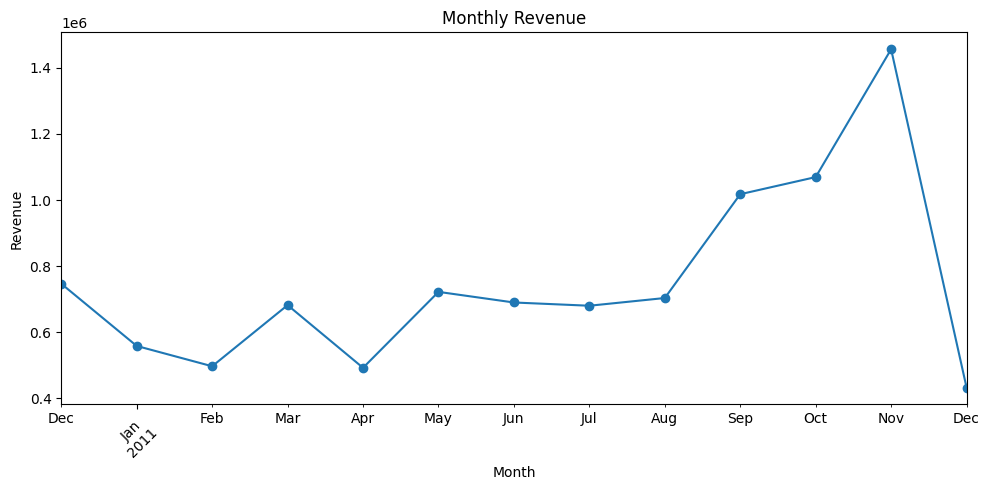

In [13]:
import matplotlib.pyplot as plt

monthly_sales.plot(kind="line", marker="o", figsize=(10, 5))

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
country_sales = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(country_sales.head(10))

Country
United Kingdom\r    8189252.30
Netherlands\r        284661.54
EIRE\r               262993.38
Germany\r            221509.47
France\r             197317.11
Australia\r          137009.77
Switzerland\r         56363.05
Spain\r               54756.03
Belgium\r             40910.96
Sweden\r              36585.41
Name: Revenue, dtype: float64


) missing from font(s) DejaVu Sans.l\Temp\ipykernel_29600\2184215586.py:9: UserWarning: Glyph 13 (
  plt.tight_layout()
) missing from font(s) DejaVu Sans.l\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 13 (
  fig.canvas.print_figure(bytes_io, **kw)


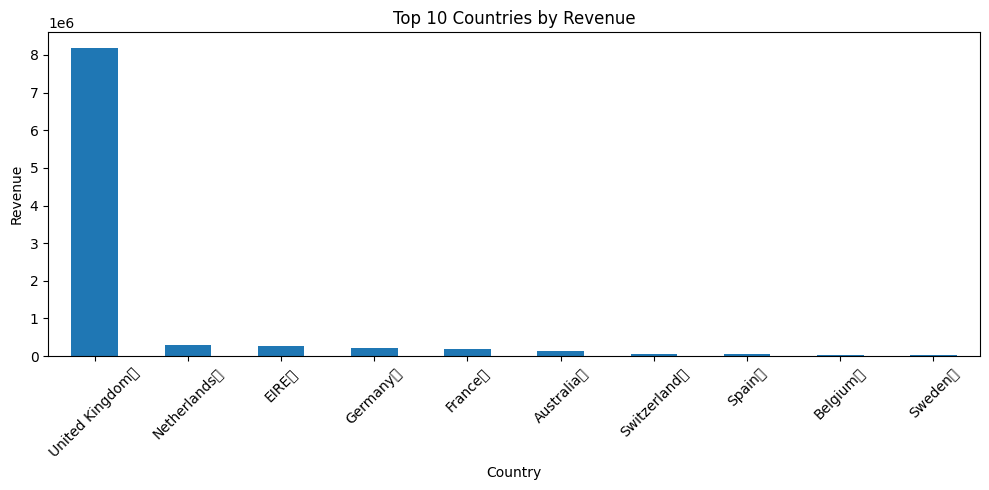

In [16]:
top_countries = country_sales.head(10)

top_countries.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



) missing from font(s) DejaVu Sans.l\Temp\ipykernel_29600\2476562676.py:9: UserWarning: Glyph 13 (
  plt.tight_layout()
) missing from font(s) DejaVu Sans.l\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 13 (
  fig.canvas.print_figure(bytes_io, **kw)


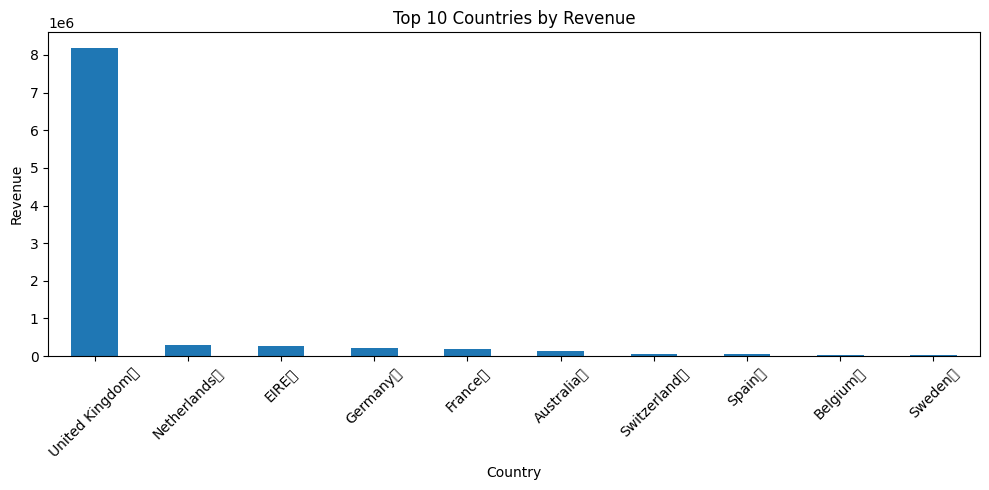

In [17]:
top_countries = country_sales.head(10)

top_countries.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
product_sales = (
    df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(product_sales.head(10))

Description
DOTCOM POSTAGE                        206245.48
REGENCY CAKESTAND 3 TIER              164459.49
WHITE HANGING HEART T-LIGHT HOLDER     99612.42
PARTY BUNTING                          98243.88
JUMBO BAG RED RETROSPOT                92175.79
RABBIT NIGHT LIGHT                     66661.63
POSTAGE                                66230.64
PAPER CHAIN KIT 50'S CHRISTMAS         63715.24
ASSORTED COLOUR BIRD ORNAMENT          58792.42
CHILLI LIGHTS                          53746.66
Name: Revenue, dtype: float64


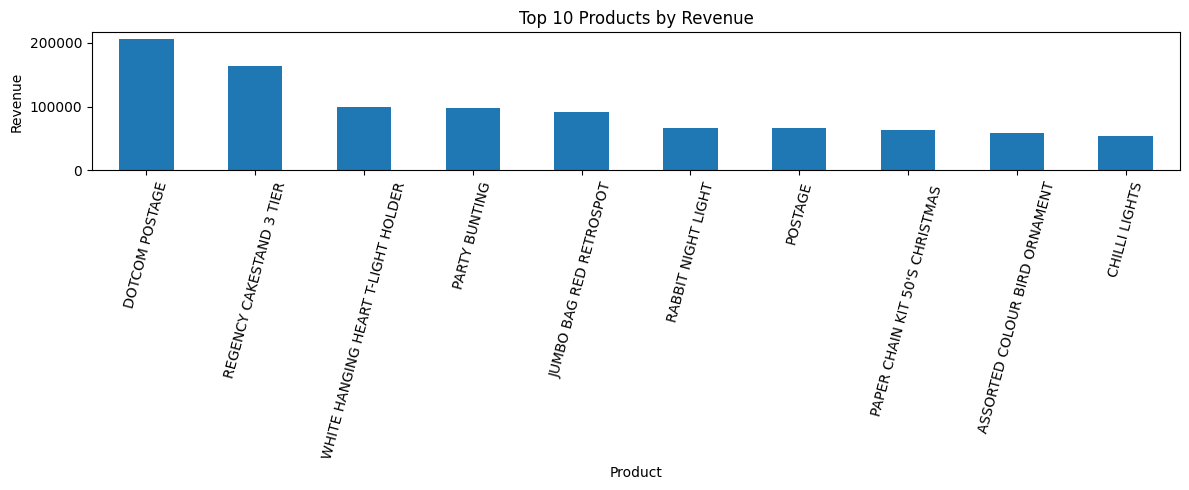

In [19]:
top_products = product_sales.head(10)

top_products.plot(kind="bar", figsize=(12, 5))

plt.title("Top 10 Products by Revenue")
plt.xlabel("Product")
plt.ylabel("Revenue")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [20]:
customer_sales = (
    df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(customer_sales.head(10))

CustomerID
14646.0    279489.02
18102.0    256438.49
17450.0    187322.17
14911.0    132458.73
12415.0    123725.45
14156.0    113214.59
17511.0     88125.38
16684.0     65892.08
13694.0     62690.54
15311.0     59284.19
Name: Revenue, dtype: float64


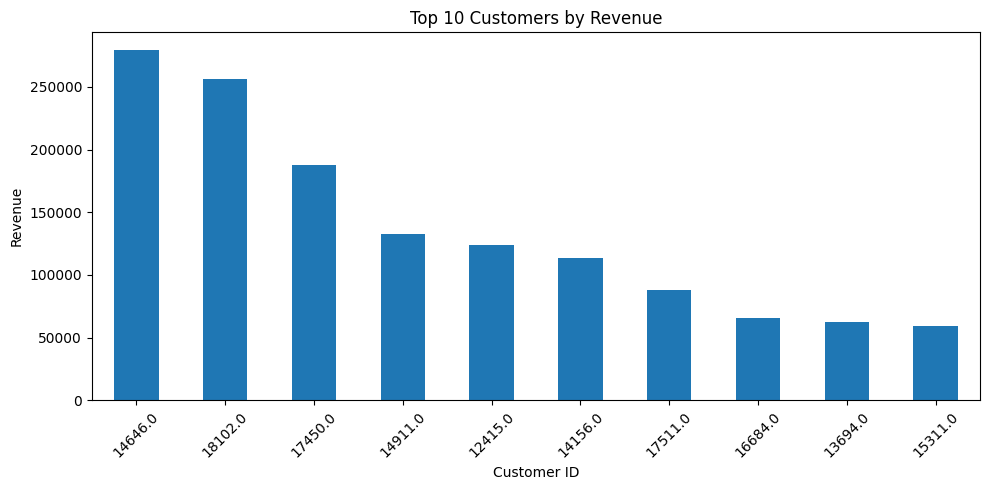

In [21]:
top_customers = customer_sales.head(10)

top_customers.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
order_sales = (
    df.groupby("InvoiceNo")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("\nTop 10 Orders by Revenue:")
print(order_sales.head(10))



Top 10 Orders by Revenue:
InvoiceNo
581483    168469.60
541431     77183.60
574941     52940.94
576365     50653.91
556444     38970.00
567423     31698.16
556917     22775.93
572209     22206.00
567381     22104.80
563614     21880.44
Name: Revenue, dtype: float64


In [23]:
product_quantity = (
    df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

print("\nTop 10 Products by Quantity Sold:")
print(product_quantity.head(10))



Top 10 Products by Quantity Sold:
Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     53751
JUMBO BAG RED RETROSPOT               47256
POPCORN HOLDER                        36322
ASSORTED COLOUR BIRD ORNAMENT         36282
PACK OF 72 RETROSPOT CAKE CASES       36016
WHITE HANGING HEART T-LIGHT HOLDER    35294
RABBIT NIGHT LIGHT                    30631
MINI PAINT SET VINTAGE                26437
PACK OF 12 LONDON TISSUES             26095
PACK OF 60 PINK PAISLEY CAKE CASES    24719
Name: Quantity, dtype: int64


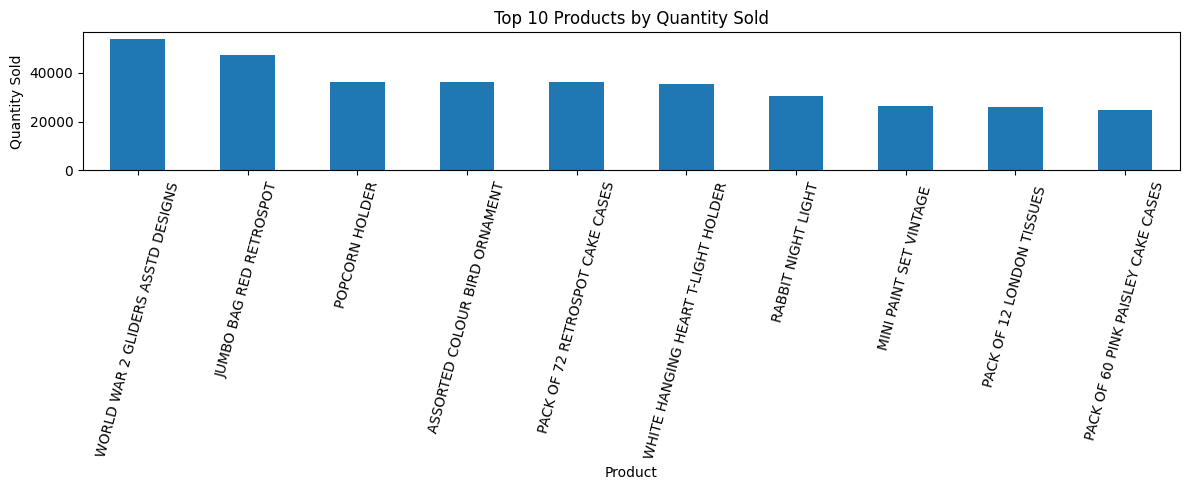

In [24]:
product_quantity.head(10).plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Product")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [25]:
yearly_sales = (
    df.groupby("Year")["Revenue"]
    .sum()
)

print("\nYearly Revenue:")
print(yearly_sales)



Yearly Revenue:
Year
2010     746723.61
2011    9001407.46
Name: Revenue, dtype: float64


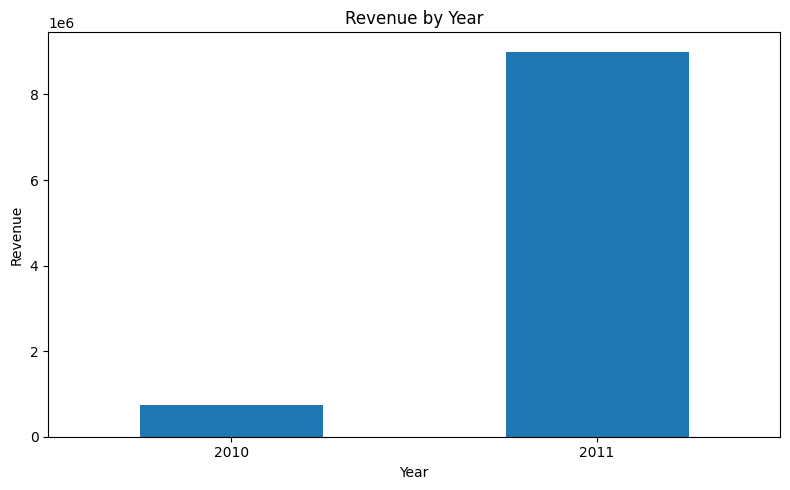

In [26]:
yearly_sales.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Revenue by Year")
plt.xlabel("Year")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [27]:
average_order_value = (
    df.groupby("InvoiceNo")["Revenue"]
    .sum()
    .mean()
)

print("\nAverage Order Value:", round(average_order_value, 2))



Average Order Value: 409.65


In [28]:
customer_orders = (
    df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)
print("\nTop 10 Customers by Number of Orders:")
print(customer_orders.head(10))




Top 10 Customers by Number of Orders:
CustomerID
14911.0    248
12748.0    223
17841.0    169
14606.0    128
13089.0    118
15311.0    118
12971.0     89
14527.0     86
13408.0     81
16029.0     76
Name: InvoiceNo, dtype: int64


In [29]:

monthly_sales.to_csv("monthly_sales.csv")
country_sales.to_csv("country_sales.csv")
product_sales.to_csv("product_sales.csv")
customer_sales.to_csv("customer_sales.csv")
customer_orders.to_csv("customer_orders.csv")

print("\nAnalysis files saved successfully.")


Analysis files saved successfully.
